# Log shape novelty: when each log shape was first seen

## Config

In [1]:
import sys
from pathlib import Path

import pandas as pd

ROOT = Path.cwd().parent
sys.path.insert(0, str(ROOT))

from logstore.db import connect

conn = connect()

import matplotlib.pyplot as plt

FIGURE_PATH = ROOT / "docs" / "figures" / "log_shape_novelty.png"

## First log of every log shape

In [2]:
first_seen = pd.read_sql(
    """
    SELECT s.id AS log_shape_id, s.component, s.state, s.template, MIN(l.ts) AS first_seen
    FROM logs l JOIN log_shapes s ON s.id = l.log_shape_id
    WHERE l.bad_time = 0
    GROUP BY s.id
    """,
    conn,
    parse_dates=["first_seen"],
)
print(f"{len(first_seen)} log shapes, first seen from {first_seen.first_seen.min()} to {first_seen.first_seen.max()}")

141 log shapes, first seen from 2003-07-31 11:04:04 to 2006-04-20 16:56:56


## New log shapes per month

In [3]:
months = pd.period_range(first_seen.first_seen.min(), first_seen.first_seen.max(), freq="M")
per_month = first_seen.first_seen.dt.to_period("M").value_counts().reindex(months, fill_value=0)
print(f"{(per_month > 0).sum()} of {len(per_month)} months bring at least one new log shape")
per_month[per_month > 0].rename("new log shapes").to_frame().T

21 of 34 months bring at least one new log shape


,2003-07,2003-08,2003-12,2004-01,2004-02,2004-03,2004-04,2004-05,2004-06,2004-09,...,2005-02,2005-03,2005-04,2005-05,2005-07,2005-09,2005-10,2005-11,2006-02,2006-04
new log shapes,1,1,41,36,18,4,4,5,3,1,...,1,3,3,6,1,2,2,3,1,3


## Bar chart, saved to docs/figures

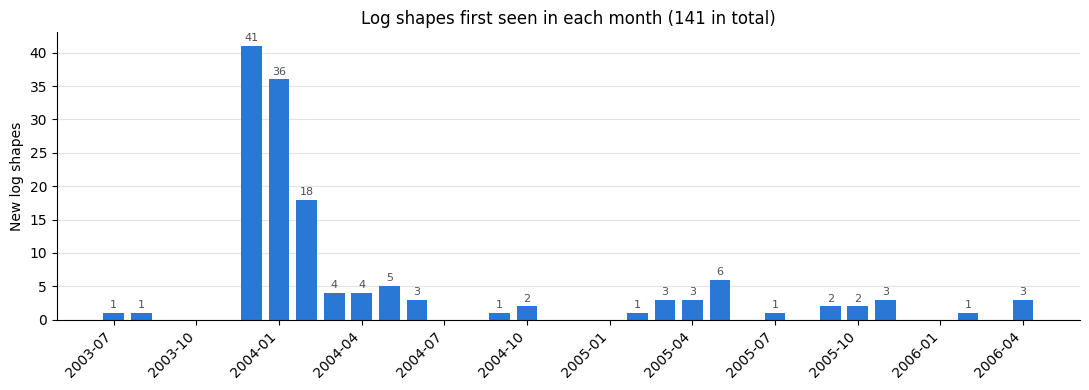

In [4]:
fig, ax = plt.subplots(figsize=(11, 4))
bars = ax.bar(range(len(per_month)), per_month.values, width=0.75, color="#2a78d6")
ax.bar_label(bars, labels=[str(n) if n else "" for n in per_month.values], padding=2, fontsize=8, color="#52514e")
# one tick per quarter, labelled with its first month
ticks = [i for i, month in enumerate(per_month.index) if month.month in (1, 4, 7, 10)]
ax.set_xticks(ticks, [per_month.index[i].strftime("%Y-%m") for i in ticks], rotation=45, ha="right")
ax.set(ylabel="New log shapes", title=f"Log shapes first seen in each month ({len(first_seen)} in total)")
ax.spines[["top", "right"]].set_visible(False)
ax.grid(axis="y", color="#e4e3df", linewidth=0.8)
ax.set_axisbelow(True)
fig.tight_layout()
FIGURE_PATH.parent.mkdir(exist_ok=True)
fig.savefig(FIGURE_PATH, dpi=150)
plt.show()

## New log shapes per quarter

In [5]:
per_quarter = first_seen.first_seen.dt.to_period("Q").value_counts().sort_index()
per_quarter.rename("new log shapes").to_frame().T

first_seen,2003Q3,2003Q4,2004Q1,2004Q2,2004Q3,2004Q4,2005Q1,2005Q2,2005Q3,2005Q4,2006Q1,2006Q2
new log shapes,2,41,58,12,1,2,4,9,3,5,1,3


## Log shapes that arrive after the first year of logs

In [6]:
year_one_end = first_seen.first_seen.min() + pd.DateOffset(years=1)
late = first_seen[first_seen.first_seen >= year_one_end].sort_values("first_seen")
late_quarters = per_quarter[per_quarter.index.start_time >= year_one_end]
print(f"{len(late)} of {len(first_seen)} log shapes are first seen after {year_one_end.date()}")
print(f"each quarter after that brings between {late_quarters.min()} and {late_quarters.max()} new log shapes")
late[["first_seen", "component", "state", "template"]].tail(10)

28 of 141 log shapes are first seen after 2004-07-31
each quarter after that brings between 1 and 9 new log shapes


,first_seen,component,state,template
134,2005-09-15 19:46:34,action,error,boot (command <N>) Error: CMF-Port This node\<...
50,2005-10-20 13:27:00,switch_module,control,no recent update
36,2005-10-28 16:15:42,clusterfilesystem,fdmn.panic,ServerFileSystem: An ServerFileSystem domain p...
51,2005-11-05 18:21:00,switch_module,control,update received
135,2005-11-06 01:28:39,action,error,wait (command <N>) Error: Console-Busy Port al...
79,2005-11-16 19:08:38,clusterfilesystem,clusterfilesystem.not_served,ClusterFileSystem: ServerFileSystem domain dom...
31,2006-02-17 16:49:09,clusterfilesystem,clusterfilesystem.no_server,ClusterFileSystem: There is no server for Serv...
4,2006-04-20 14:20:23,unix.hw,state_change.unavailable,Component State Change: Component <N>alt<N> is...
140,2006-04-20 14:20:36,unix.hw,state_change.available,Component State Change: Component <N>alt<N> is...
0,2006-04-20 16:56:56,server,subsys,failed to configure resourcemgmt subsystem err...
